In [429]:
import torch
from torch import nn, optim
import matplotlib.pyplot as plt

from utils import *

# Regression linéaire multi-variée

On se donne $n$ observations de $N$ variables explicatives et $M$ variables à
prédire qui sont reliées par une relation linéaire $Y = Xθ^⊤ + ε$ où
$Y ∈ M_{n, M}(ℝ)$, $X ∈ M_{n, N}(ℝ)$, $θ ∈ M_{M, N}(ℝ)$ et $ε ∈ M_{n, M}(ℝ)$ est
un bruit gaussien. 

In [430]:
#torch.manual_seed(123)

n = 100
N = 5
M = 3

X = 2 * torch.rand(n, N)
theta = torch.rand(M, N)
Y = X @ theta.T + torch.randn(n, M) * 0.05

In [431]:
names = ("SGD", "Spectral GD")
models = [nn.Linear(N, M, bias=False) for _ in names]

optimizers  = [
    optim.SGD(models[0].parameters(), lr=0.5),
    spectral_GD(models[1].weight, lr=0.02)
]

criterion = nn.MSELoss()

In [432]:
loss_fn = nn.MSELoss()
losses = [[] for _ in names]

epochs = 1000
for _ in range(epochs):
    for model, optimizer, loss in zip(models, optimizers, losses):
            pred = model(X)
            loss_value = loss_fn(pred, Y)
            loss.append(loss_value.item())
            loss_value.backward()
            optimizer.step()
            optimizer.zero_grad()

for name, loss in zip(names, losses):
    print(f"{name}: final loss = {loss[-1]}")

SGD: final loss = 0.0023017339408397675
Spectral GD: final loss = 0.00264893495477736


Les deux algorithmes produisent des résultats similaire mais la descente
standard est plus rapide.

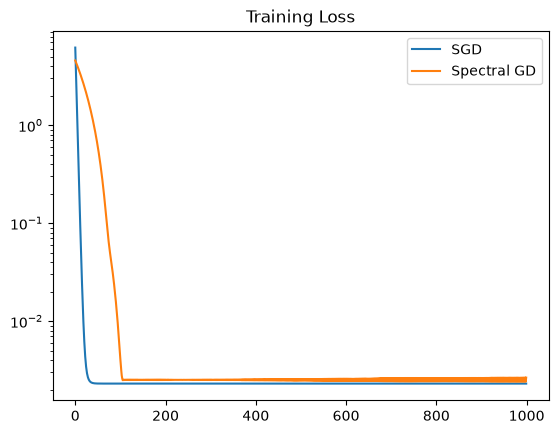

In [433]:
fig, ax = plt.subplots()
ax.set_title('Training Loss')
ax.set_yscale('log')
for name, loss in zip(names, losses):
    ax.plot(loss, label=f'{name}')
ax.legend()

plt.show()